# 从像素到动作：原始 Dreamer 的中文可运行教程

这份教程对应你上传的 **Dream to Control: Learning Behaviors by Latent Imagination**，ICLR 2020，arXiv:1912.01603v3。你称它为 Dreamer V0；下文指这篇原始 Dreamer，通常也被称为 Dreamer V1。

先抓住一个具体目标：**摄像头看见一个滑块，模型要通过一个连续控制量，让滑块移到目标位置。** 世界模型学习动作的后果；Actor 学习如何行动；Critic 估计当前策略从某个状态出发的长期回报。

这里有三套参数和三个优化器。不要把所有东西想成一个共同最小化“总 loss”的网络：

| 参数 | 包含的网络 | 训练时回答的问题 |
|---|---|---|
| θ：世界模型 | Encoder、GRU、Posterior、Prior、Decoder、Reward head | 根据真实经验，应该如何表示和预测这个世界？ |
| φ：Actor | 动作网络 | 在当前世界模型里，怎样行动能获得更多奖励？ |
| ψ：Critic | 状态价值网络 | 当前策略从这个状态继续行动，总共能获得多少折扣奖励？ |

## 1. 先运行，再对照代码

```bash
python -m pip install -r requirements.txt
python dreamer_demo.py --mode smoke --outdir smoke_results
python dreamer_demo.py --mode demo --outdir results
```

`smoke` 只检查流程和梯度，不用于展示学习成功。`demo` 默认在 CPU 上训练；如果已有支持 CUDA 的 PyTorch，可以加 `--device cuda`。示例无需 MuJoCo、Gym、预训练模型或额外数据。首次完整运行所用的版本、时间、配置和结果都保存在 `results/metrics.json`。不同设备、版本和随机种子不保证得到相同数值。

`Dreamer_Chinese.ipynb` 包含代码定义、能手算的小例子、重建梯度检查和已经执行的结果。打开 Notebook 可以先读，不必重新训练。压缩包中的 `results/checkpoint.pt` 是本次训练最后一步的权重，包含世界模型、Actor、Critic，不包含优化器状态，因此用于推断与检查，不是精确续训检查点。

建议阅读代码顺序：`PixelReach` → `WorldModel.observe` → `WorldModel.loss` → `lambda_return` → `Dreamer.imagine` → `Dreamer.train_behavior` → `train`。

本 Notebook 中的类与函数直接取自同包的 Python 实现。顺序运行即可得到全部定义；默认跳过重新训练，保留本次实际执行的结果。

In [1]:
from __future__ import annotations
import argparse
from contextlib import contextmanager
from dataclasses import asdict, dataclass
import json
from pathlib import Path
import time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Normal, kl_divergence
from IPython.display import display, Markdown, Image
@dataclass
class Config:
    seed: int = 7
    image_size: int = 16
    deter: int = 64
    stoch: int = 8
    embed: int = 64
    hidden: int = 128
    batch: int = 16
    sequence: int = 16
    horizon: int = 12
    imagination_starts: int = 64
    gamma: float = 0.97
    lam: float = 0.95
    beta: float = 1.0
    free_nats: float = 1.0
    image_sigma: float = 0.3
    reward_sigma: float = 0.3
    model_lr: float = 0.001
    actor_lr: float = 0.0003
    critic_lr: float = 0.0003
    seed_episodes: int = 32
    episode_length: int = 60
    warmup: int = 400
    cycles: int = 30
    updates_per_cycle: int = 40
    device: str = "cpu"

torch.set_num_threads(1)
torch.manual_seed(7)
print("PyTorch:", torch.__version__)

PyTorch: 2.5.1+cpu


## 2. 一条真实经验到底有哪些东西？

环境内部有滑块位置 x，目标位置是 0.35：

$$
x_{t+1}=\operatorname{clip}(x_t+0.12a_t,-1,1),\quad a_t\in[-1,1],
$$

$$
r_{t+1}=1-\left(\frac{x_{t+1}-0.35}{1.35}\right)^2.
$$

**这些坐标和环境公式不输入任何神经网络。** 公式只用于模拟环境，坐标只用于生成图像、生成真实奖励和最后评估。模型输入是一张 16×16 灰度图：上方光点是目标，下方光点是滑块。它必须从图像与动作序列中学习表示和动作后果。

目标与滑块横坐标对齐时，奖励接近 1。这个奖励是我们给任务定义的目标，不是图像重建误差，也不是“好奇心”。如果以后把 Dreamer 用到你的视觉探索研究，信息增益或学习进步是需要另外定义的奖励机制；原始 Dreamer 本身不自动提供这种驱动力。

一次交互得到 `(o_t, a_t, r_{t+1}, o_{t+1})`，存进 Replay。整个片段是：

| 张量 | 默认形状 | 内容 |
|---|---|---|
| `obs` | `[16,17,1,16,16]` | B=16 个片段，每段 L+1=17 张图 |
| `actions` | `[16,16,1]` | 每相邻两张图之间的实际动作 |
| `rewards` | `[16,16]` | 每次动作执行后获得的真实奖励 |
| `h` | `[16,17,64]` | 确定性历史状态 |
| `z` | `[16,17,8]` | 随机潜变量 |
| `features` | `[16,17,72]` | 把 h 和 z 拼接起来的完整模型状态 |

本教程把执行 a_t 后得到的奖励记成 r_{t+1}。论文及其他实现可能使用 r_t。只要状态、动作、奖励在代码中对齐，索引平移不改变算法。本代码在 `feat[:,1:]` 上预测 `rewards`，不是在 `feat[:,:-1]` 上预测。

In [2]:
class PixelReach:
    """只输出灰度图。x 和 goal 仅用于环境生成奖励/图像及最终评估。

    x_next = clip(x + 0.12 * a, -1, 1)
    r_next = 1 - ((x_next - 0.35) / 1.35)^2
    上面的光点表示目标，下面的光点表示滑块。两个光点横坐标相同即成功。
    没有真正的终止状态；60 步只是截取一段数据，不能把它当作死亡。
    """
    goal = 0.35

    def __init__(self, seed=0, size=16):
        self.rng = np.random.default_rng(seed)
        self.size = size
        self.yy, self.xx = np.mgrid[:size, :size]
        self.reset()

    def reset(self, x=None):
        self.x = float(self.rng.uniform(-0.95, 0.95) if x is None else x)
        return self.render()

    def render(self):
        def blob(x, y):
            px = 1.5 + (x + 1) * (self.size - 4) / 2
            return np.exp(-((self.xx - px)**2 + (self.yy - y)**2) / (2 * 1.15**2))
        im = 0.85 * blob(self.goal, 3.5) + blob(self.x, 11.0)
        return np.clip(im, 0, 1).astype(np.float32)[None]  # [C=1,16,16]

    def step(self, action):
        self.x = float(np.clip(self.x + 0.12 * np.clip(action, -1, 1), -1, 1))
        reward = 1.0 - ((self.x - self.goal) / 1.35)**2
        return self.render(), float(reward)

class Replay:
    def __init__(self, seed):
        self.episodes = []
        self.rng = np.random.default_rng(seed)

    def add(self, episode):
        self.episodes.append(episode)

    def sample(self, batch, length, device):
        chunks = []
        for _ in range(batch):
            ep = self.episodes[int(self.rng.integers(len(self.episodes)))]
            start = int(self.rng.integers(len(ep["actions"]) - length + 1))
            chunks.append({
                "obs": ep["obs"][start:start + length + 1],
                "actions": ep["actions"][start:start + length],
                "rewards": ep["rewards"][start:start + length],
            })
        return {key: torch.as_tensor(np.stack([c[key] for c in chunks]), device=device)
                for key in chunks[0]}

def mlp(nin, nout, hidden=128):
    return nn.Sequential(nn.Linear(nin, hidden), nn.ELU(),
                         nn.Linear(hidden, hidden), nn.ELU(), nn.Linear(hidden, nout))

In [3]:
env = PixelReach(seed=0)
obs_list = [env.reset(x=-0.8)]
action_list, reward_list = [], []
for t in range(16):
    action = 0.5
    obs, reward = env.step(action)
    obs_list.append(obs)
    action_list.append([action])
    reward_list.append(reward)
batch = {
    'obs': torch.tensor(np.array(obs_list)[None]),
    'actions': torch.tensor(np.array(action_list, dtype=np.float32)[None]),
    'rewards': torch.tensor(np.array(reward_list, dtype=np.float32)[None]),
}
print({key: tuple(value.shape) for key, value in batch.items()})
print('一条片段的真实奖励:', np.round(reward_list[:5], 3))

{'obs': (1, 17, 1, 16, 16), 'actions': (1, 16, 1), 'rewards': (1, 16)}
,一条片段的真实奖励: [0.348 0.418 0.484 0.546 0.604]


## 3. RSSM 里为什么既有 h，又有 z？

令模型状态 s_t=(h_t,z_t)。先根据过去状态和动作更新记忆：

$$
h_t=\operatorname{GRU}_\theta(h_{t-1},[z_{t-1},a_{t-1}]).
$$

**h_t 是确定性计算出来的历史摘要。** 这里“确定性”是指给定上一步状态和动作，GRU 的这次计算没有额外抽样；并不表示整个轨迹没有随机性。

接下来有两种得到 z_t 的方式。

**Prior：还没看见当前图像时，根据历史预测。**

$$
p^{\mathrm{prior}}_\theta(z_t\mid h_t)
=\mathcal N(\mu^p_t,\operatorname{diag}((\sigma^p_t)^2)).
$$

**Posterior：看见当前图像后，结合图像纠正状态判断。**

$$
e_t=\operatorname{Encoder}_\theta(o_t),\quad
p^{\mathrm{post}}_\theta(z_t\mid h_t,e_t)
=\mathcal N(\mu^q_t,\operatorname{diag}((\sigma^q_t)^2)).
$$

训练世界模型时，用 Posterior 的样本 z_t；想象未来时没有未来图像，只能用 Prior。两者不是“旧网络和新网络”，而是同一个世界模型里的两个不同条件分布。论文用 p 表示 representation、q 表示 transition；本教程用 prior/posterior 名称避免其他 VAE 文献的 p/q 记号造成混淆。

代码里：

```python
embedding = encoder(image)
h = rnn(torch.cat([previous_z, previous_action], -1), previous_h)
prior = distribution(prior_net(h))
posterior = distribution(posterior_net(torch.cat([h, embedding], -1)))
z = posterior.rsample()
s = torch.cat([h, z], -1)
```

为什么要用分布？像素历史不能完整确定世界，模型还要表达状态的不确定性。这里的 z 并不预先规定哪一维是位置、速度或距离。能够解码图像也不意味着每一维自动获得了人类可解释的物理意义。

In [4]:
class WorldModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        # 小图像使用 MLP，避免卷积尺寸计算掩盖核心逻辑；论文采用 CNN。
        self.encoder = mlp(cfg.image_size**2, cfg.embed, cfg.hidden)
        self.rnn = nn.GRUCell(cfg.stoch + 1, cfg.deter)
        self.prior = mlp(cfg.deter, 2 * cfg.stoch, cfg.hidden)
        self.posterior = mlp(cfg.deter + cfg.embed, 2 * cfg.stoch, cfg.hidden)
        self.decoder = mlp(cfg.deter + cfg.stoch, cfg.image_size**2, cfg.hidden)
        self.reward = mlp(cfg.deter + cfg.stoch, 1, cfg.hidden)

    def initial(self, batch):
        p = next(self.parameters())
        return (p.new_zeros(batch, self.cfg.deter), p.new_zeros(batch, self.cfg.stoch))

    @staticmethod
    def distribution(stats):
        mean, raw_std = stats.chunk(2, -1)
        return Normal(mean, F.softplus(raw_std) + 0.1)

    @staticmethod
    def features(state):
        return torch.cat(state, dim=-1)  # s_t = [h_t, z_t]

    def prior_step(self, state, action, sample=True):
        h, z = state
        h = self.rnn(torch.cat([z, action], -1), h)
        prior = self.distribution(self.prior(h))
        z = prior.rsample() if sample else prior.mean
        return (h, z), prior

    def posterior_at(self, h, embedding, sample=True):
        posterior = self.distribution(self.posterior(torch.cat([h, embedding], -1)))
        z = posterior.rsample() if sample else posterior.mean
        return (h, z), posterior

    def infer_observation(self, obs, previous=None, action=None, sample=False):
        # 与环境交互：每获得一张新图像，都用 posterior 纠正状态估计。
        h = self.initial(len(obs))[0] if previous is None else self.prior_step(previous, action, sample)[0][0]
        embedding = self.encoder(obs.flatten(start_dim=-3))
        return self.posterior_at(h, embedding, sample)[0]

    def observe(self, obs, actions, sample=True):
        # obs: [B,L+1,1,16,16], actions: [B,L,1]
        embedding = self.encoder(obs.flatten(start_dim=-3))
        state = self.initial(obs.shape[0])
        states, kls = [], []
        for t in range(obs.shape[1]):
            if t == 0:
                h = state[0]
                prior = self.distribution(self.prior(h))
            else:
                (h, _), prior = self.prior_step(state, actions[:, t - 1], sample)
            state, posterior = self.posterior_at(h, embedding[:, t], sample)
            # 本文变量名采用 posterior / prior，避免不同文献 p/q 的符号反转。
            kls.append(kl_divergence(posterior, prior).sum(-1))
            states.append(state)
        h = torch.stack([s[0] for s in states], 1)
        z = torch.stack([s[1] for s in states], 1)
        return (h, z), torch.stack(kls, 1)

    def decode(self, features):
        mean = self.decoder(features).sigmoid()
        return mean.reshape(*features.shape[:-1], 1, self.cfg.image_size, self.cfg.image_size)

    def loss(self, batch):
        states, kl = self.observe(batch["obs"], batch["actions"])
        feat = self.features(states)
        reconstructed = self.decode(feat)
        # Gaussian NLL，省去固定常数。先按事件维求和，再按 batch/time 平均。
        image_loss = (0.5 * ((reconstructed - batch["obs"]) / self.cfg.image_sigma)**2).sum((-3, -2, -1)).mean()
        reward_prediction = self.reward(feat[:, 1:]).squeeze(-1)
        reward_loss = (0.5 * ((reward_prediction - batch["rewards"]) / self.cfg.reward_sigma)**2).mean()
        kl_loss = kl.clamp_min(self.cfg.free_nats).mean()
        loss = image_loss + reward_loss + self.cfg.beta * kl_loss
        metrics = dict(model_loss=loss.item(), image_nll=image_loss.item(),
                       reward_nll=reward_loss.item(), kl=kl.mean().item())
        return loss, states, metrics

In [5]:
wm = WorldModel(Config())
states, kl = wm.observe(batch['obs'], batch['actions'])
print('h:', tuple(states[0].shape), 'z:', tuple(states[1].shape))
print('完整状态:', tuple(wm.features(states).shape))
print('重建图像:', tuple(wm.decode(wm.features(states)).shape))

h: (1, 17, 64) z: (1, 17, 8)
,完整状态: (1, 17, 72)
,重建图像: (1, 17, 1, 16, 16)


## 4. Reconstruction 到底在重建什么？

它首先重建**同一时刻的真实图像 o_t**：

$$
s_t\longrightarrow\operatorname{Decoder}_\theta\longrightarrow\hat o_t.
$$

真实图像既被用于推断 Posterior，也被用作重建目标。这就是自监督：不需要人为标注“滑块在这里”，但需要模型通过有限的潜状态，把图像中有用的信息保存下来。

比如真实图像里，滑块在左边。Decoder 却把滑块画在中间。逐像素比较两张图，就会在“真实滑块所在处”和“错误画出的滑块所在处”产生误差。反向传播会同时调整 Decoder，以及产生 s_t 的 Encoder、Posterior、GRU，使这个潜状态以后更容易还原出正确图像。

Decoder 不是额外看到了一张正确答案后复制它：Decoder 的输入只有 s_t。完整模型是由 Encoder/Posterior 压缩，再由 Decoder 还原。重建目标要求压缩表示保留信息，动态一致性还要靠下面的 Prior/KL。

代码把每个像素看作具有固定标准差 σ_o 的高斯观测：

$$
p(o_t\mid s_t)=\mathcal N(\hat o_t,\sigma_o^2I),
$$

$$
\mathcal L_{\mathrm{image}}
=\frac{1}{BT}\sum_{b,t}\frac{\|o_{b,t}-\hat o_{b,t}\|^2}{2\sigma_o^2}.
$$

这就是忽略固定常数后的负对数似然。**最大化真实图像的 likelihood，等价于最小化这个缩放后的平方误差。** 先对图像的像素维求和，再对 batch/time 平均；换成所有元素直接 `.mean()` 会改变相对于 KL 和奖励损失的比例。

重建得好只说明“看到图像后，可以编码并还原”。为了检验动力学，还要做独立的 **open-loop prediction**：只给前 5 张图，后面只给动作，用 Prior 连续预测。代码会同时输出这两种图，不能把它们的效果混称为预测准确率。

下面只反传图像重建损失，查看哪些子网络得到梯度。这里是随机初始化网络的计算图检查，不是训练效果评估。

In [6]:
wm.zero_grad(set_to_none=True)
states, _ = wm.observe(batch['obs'], batch['actions'])
reconstruction = wm.decode(wm.features(states))
image_loss = 0.5 * ((reconstruction-batch['obs'])/wm.cfg.image_sigma).square().sum((-3,-2,-1)).mean()
image_loss.backward()
def gradient_norm(module):
    return float(sum((p.grad.square().sum() for p in module.parameters() if p.grad is not None), torch.tensor(0.)).sqrt())
for name in ['encoder','rnn','posterior','decoder','prior','reward']:
    print(f'{name:10s}: {gradient_norm(getattr(wm,name)):.6f}')
assert gradient_norm(wm.encoder) > 0
assert gradient_norm(wm.decoder) > 0
assert gradient_norm(wm.prior) == 0
print('Prior 不直接收到这个 reconstruction loss；它需要 KL 训练信号。')

encoder   : 0.267976
,rnn       : 4.236322
,posterior : 1.542593
,decoder   : 31.859356
,prior     : 0.000000
,reward    : 0.000000
,Prior 不直接收到这个 reconstruction loss；它需要 KL 训练信号。


## 5. 世界模型为什么还需要奖励预测和 KL？

**奖励预测**学习真实环境的评分规则：

$$
\hat r_t=R_\theta(s_t),\qquad
\mathcal L_r=\frac{1}{BT}\sum_{b,t}\frac{(r_{b,t}-\hat r_{b,t})^2}{2\sigma_r^2}.
$$

奖励 head 不会设计任务目标，它拟合 Replay 里实际得到的奖励。以后在没有真实环境参与的想象中，才可以使用 $\hat r$ 给动作后果评分。本例奖励只依赖到达的位置，因此从到达状态预测奖励是自洽的。

**KL 让没看图像的 Prior 接近看过图像的 Posterior：**

$$
\mathcal L_{\mathrm{KL}}
=D_{\mathrm{KL}}(p^{\mathrm{post}}_\theta(z_t\mid h_t,e_t)
\|p^{\mathrm{prior}}_\theta(z_t\mid h_t)).
$$

对角高斯的 KL 可以直接算，无需再抽样估计：

$$
D_{\mathrm{KL}}(q\|p)=\frac12\sum_i
\left[\log\frac{(\sigma_i^p)^2}{(\sigma_i^q)^2}
+\frac{(\sigma_i^q)^2+(\mu_i^q-\mu_i^p)^2}{(\sigma_i^p)^2}-1\right].
$$

假设 Posterior 看图后认为“滑块应该在左边”，Prior 根据先前动作却预测“在右边”，KL 就会惩罚这两个分布的不一致。标准联合 KL 同时作用于两端：既训练 Prior，也限制 Posterior 任意编码、与历史完全脱节。重建和奖励目标则要求 Posterior 仍然保留有用信息。

总目标对应论文式 (10) 的负号版本：

$$
\boxed{\mathcal L_{\mathrm{WM}}=
\mathcal L_{\mathrm{image}}+\mathcal L_r+
\beta\,\operatorname{mean}_{b,t}\max(\kappa,\mathrm{KL}_{b,t}).}
$$

κ 是 free nats。KL 低于这个阈值时不继续施加缩小它的梯度压力，给表示留一点信息容量；不是把 KL 强行变成 0。本 demo 用 κ=1，原论文用 3。

```python
model_optimizer.zero_grad()
loss = image_loss + reward_loss + beta * kl_loss
loss.backward()
model_optimizer.step()
```

只更新 θ。Actor 和 Critic 此时没有参与。特别注意：这里 `prior_net` 的直接训练信号主要来自 KL，不能以为图像 reconstruction loss 会直接穿过未使用的 Prior 样本。

In [7]:
wm.zero_grad(set_to_none=True)
_, kl = wm.observe(batch['obs'], batch['actions'])
kl.mean().backward()  # 展示未截断 KL 的梯度；完整训练使用 free nats
print('KL -> Prior 梯度范数:', gradient_norm(wm.prior))
assert gradient_norm(wm.prior) > 0
loss, states, components = wm.loss(batch)
print('完整 WM loss 的三部分:', components)

KL -> Prior 梯度范数: 0.833167314529419
,完整 WM loss 的三部分: {'model_loss': 314.3549499511719, 'image_nll': 310.1590576171875, 'reward_nll': 3.195880889892578, 'kl': 0.10288869589567184}


## 6. RL 训练时，究竟“梦见”了什么？

从真实 Replay 片段推断出一个状态 s_0，把它 detach，作为想象起点。接下来不调用环境，也不获取新图像：

$$
a_0\sim\pi_\phi(\cdot\mid s_0),\quad
s_1\sim P_\theta(\cdot\mid s_0,a_0),\quad
\hat r_1=R_\theta(s_1).
$$

继续得到 s_2、s_3……s_H。所有这些是紧凑的向量，并不是一部先生成出来再拿给策略看的视频。Decoder 可以为了检查把它们画出来，但 Actor/Critic 的训练不需要这个解码过程。

```python
features = [start_state]
rewards = []
for t in range(H):
    action = actor(features[-1])
    next_state = world_model_prior(features[-1], action)
    rewards.append(reward_head(next_state))
    features.append(next_state)
```

默认一次从真实数据选 64 个起点，每个起点想象 12 步。得到的 `features` 是 `[13,64,72]`，`rewards` 是 `[12,64]`。Actor 学习以状态为条件的连续动作分布；并非给每个动作 a 固定分配一个永久不变的价值。

In [8]:
class Actor(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = mlp(cfg.deter + cfg.stoch, 2, cfg.hidden)

    def forward(self, feat, sample=True):
        raw_mean, raw_std = self.net(feat).chunk(2, -1)
        mean = 5 * torch.tanh(raw_mean / 5)
        std = F.softplus(raw_std) + 0.1
        # rsample = mean + std * epsilon，保留动作相对于 Actor 参数的梯度。
        u = Normal(mean, std).rsample() if sample else mean
        return torch.tanh(u)

## 7. Critic 在预测什么？为什么不能只加 12 步奖励？

Critic 预测的是当前策略与当前世界模型下的长期状态价值：

$$
V_\psi(s_t)\approx
\mathbb E_{P_\theta,\pi_\phi}\left[\sum_{k=0}^{\infty}\gamma^k\hat r_{t+k+1}\mid s_t\right].
$$

Reward head 预测一步奖励，Critic 预测未来许多步的总和。哪怕两个状态立即奖励相同，如果后续前景不同，Critic 也可以给出不同估值。

只加有限 H 步奖励，会漏掉 H 步以后的好处。可以把末端状态 s_H 交给 Critic，估计从它出发后面的奖励：

$$
\hat r_1+\gamma\hat r_2+\cdots+
\gamma^{H-1}\hat r_H+\gamma^H V_\psi(s_H).
$$

最后一项叫 bootstrap。**停止想象是因为计算预算到头，不代表机器人死亡或后面没有奖励。**

## 8. λ-return 用一组数字算清楚

1-step target 使用一步预测奖励和下一个状态的价值；2-step target 使用两步奖励，再接后面的价值。更多真实的模型 rollout 会减少对近端 Critic 估值的依赖，也会积累更多模型误差与抽样噪声。λ-return 对不同长度的 target 作指数加权，原论文式 (5)、(6) 表达的就是这件事。

在代码里，从后往前递推最容易：

$$
G_H=V_\psi(s_H),
$$

$$
\boxed{G_t=\hat r_{t+1}+\gamma[(1-\lambda)V_\psi(s_{t+1})+\lambda G_{t+1}].}
$$

例如 H=3，γ=0.9，λ=0.5，预测奖励是 `[1,2,3]`，下一状态价值是 `[10,20,30]`：

| 次序 | 计算 | 结果 |
|---|---|---|
| 边界 | G₃=V(s₃) | 30 |
| 最后一步 | G₂=3+0.9×(0.5×30+0.5×30) | 30 |
| 中间一步 | G₁=2+0.9×(0.5×20+0.5×30) | 24.5 |
| 第一步 | G₀=1+0.9×(0.5×10+0.5×24.5) | 16.525 |

这些数字只是用于核对公式的假设输入，不是训练结果。实现会实际计算并 assert 这三个答案。λ=0 变成一步 bootstrap；λ=1 变成全部 H 步预测奖励加末端 bootstrap，仍然不是无限长的真实环境 Monte Carlo 回报。

In [9]:
def lambda_return(rewards, next_values, gamma=0.97, lam=0.95):
    """rewards[t]=r_(t+1), next_values[t]=V(s_(t+1)); 都是 [H,N]。

    G_H = V(s_H)
    G_t = r_(t+1) + gamma * ((1-lambda)*V(s_(t+1)) + lambda*G_(t+1))
    同一个函数产生两种用途：Actor 保留梯度；Critic target 必须 detach。
    """
    if rewards.shape != next_values.shape or rewards.shape[0] == 0:
        raise ValueError("rewards and next_values must have equal, nonempty [H,N] shape")
    longer_return = next_values[-1]
    reverse = []
    for t in reversed(range(len(rewards))):
        longer_return = rewards[t] + gamma * ((1 - lam) * next_values[t] + lam * longer_return)
        reverse.append(longer_return)
    return torch.stack(reverse[::-1])

In [10]:
rewards = torch.tensor([[1.], [2.], [3.]])
next_values = torch.tensor([[10.], [20.], [30.]])
returns = lambda_return(rewards, next_values, gamma=0.9, lam=0.5)
print('G0, G1, G2 =', returns[:,0].tolist())
torch.testing.assert_close(returns[:,0], torch.tensor([16.525,24.5,30.]))

G0, G1, G2 = [16.524999618530273, 24.5, 30.0]


## 9. Critic 的 loss：把 G 当成固定标签

$$
\mathcal L_V=\frac12\operatorname{mean}_t
\left[w_t(V_\psi(s_t)-\operatorname{sg}(G_t))^2\right].
$$

`sg` 就是 stop gradient。假设 Critic 对 s₀ 当前预测 10，刚才构造的 target 是 16.525，则本次优化应把预测朝 16.525 移动。

```python
prediction = critic(imagined_states[:-1].detach())
target = returns.detach()
critic_loss = 0.5 * (prediction - target).square().mean()
critic_loss.backward()
critic_optimizer.step()
```

target 中确实包含 Critic 自己的输出。这叫 TD bootstrap，但这次回归把整份 target 暂时固定，否则优化器也会沿标签那一边改变它，变成另外一个目标。

“那它是不是自己编答案、自己学？”它仍有来自真实经验的锚点：Reward head 用真实奖励监督，动力学用真实图像和动作监督。Critic 学习这些预测奖励的长期累积。考虑奖励总为 1、γ=0.9、只有一个状态的简化例子：从 V=0 开始，每次精确更新 target `1+0.9V`，会得到 1、1.9、2.71……趋近 10，而非永远维持 0。

在固定模型和固定策略、精确更新的情形，Bellman 算子满足 $\|T V-T U\|_\infty\le\gamma\|V-U\|_\infty$，提供这个固定点的数学依据。它不保证实际神经网络、变化中的策略与有误差的世界模型都稳定收敛。真实经验不足时，Actor 仍可能利用世界模型的错误；持续收集真实数据并更新世界模型非常关键。

In [11]:
value = 0.0
values = []
for iteration in range(10):
    value = 1 + 0.9*value
    values.append(value)
print('Bellman 精确更新示例:', np.round(values,4))
print('固定点:', 1/(1-0.9))

Bellman 精确更新示例: [1.     1.9    2.71   3.439  4.0951 4.6856 5.217  5.6953 6.1258 6.5132]
,固定点: 10.000000000000002


## 10. Actor 的 loss：让动作通过模型改变未来

$$
\mathcal L_\pi=-\operatorname{mean}_t[w_tG_t],\qquad
w_t=\gamma^t.
$$

前面的负号使梯度下降最大化回报。与 Critic 回归那一步不同，**这里不能把 G detach**。我们需要知道：动作稍微改变，未来状态会怎么变，奖励和价值又会怎么变。

例如其中一条梯度路径是：

$$
\phi\longrightarrow a_t\longrightarrow s_{t+1}
\longrightarrow \hat r_{t+1}\longrightarrow G_t
\longrightarrow\mathcal L_\pi.
$$

另一条经过 $V_\psi(s_{t+1})$，更多路径还经过后面多个时刻。以一步奖励为例：

$$
\frac{\partial\hat r_{t+1}}{\partial\phi}
=\frac{\partial R_\theta}{\partial s_{t+1}}
\frac{\partial s_{t+1}}{\partial a_t}
\frac{\partial a_t}{\partial\phi},
$$

这只是完整多步链式求导中的一条分支。默认示例把 Actor 对想象状态的依赖也保留在计算图中。

这里的 w_t 是算出来的固定权重，不是可训练参数。存在真实提前终止时，可用累计 continuation/discount 预测给时间步加权；本例没有真实终止，不训练 continuation head。60 步片段结尾是截断，不设 c=0。

## 11. 冻结 θ，为什么仍然能穿过 θ 反传？

把这件事缩到一个能手算的函数。设当前位置 x=-0.6，Actor 参数 $\phi$=0：

$$
a=\tanh\phi,\quad x'=-0.6+0.5a,\quad r=1-(x')^2,\quad L=-r.
$$

这里 0.5 是固定“世界模型”的系数，不训练它；这个独立算例也不是前面训练模型的真实网络。链式法则仍然给出：

$$
\frac{dL}{d\phi}=2x'\cdot0.5\cdot(1-\tanh^2\phi)=-0.6.
$$

学习率 0.1 时，φ 更新到 0.06，动作变成约 0.0599，x' 变成约 -0.5700，奖励从 0.6400 上升到约 0.6751。**固定函数系数不会消除这个函数对输入的导数。**

```python
with freeze_parameters(world_model, critic):
    imagined_states, rewards = imagine(start_state)
    values = critic(imagined_states)
    returns = lambda_return(rewards, values[1:])
    actor_loss = -returns.mean()
    actor_loss.backward()
    actor_optimizer.step()
```

在这一步，世界模型和 Critic 的参数不求梯度、不更新，但它们的运算仍被 autograd 记录。若把整个想象包进 `with torch.no_grad()`，或把 `returns` detach，所需的动作到回报的路径就会断开。

| 当前阶段 | 更新 θ | 更新 φ | 更新 ψ | 要保留的梯度 |
|---|---|---|---|---|
| World model | 是 | 否 | 否 | 真实图像/奖励/KL → 表示与动力学网络 |
| Actor | 否 | 是 | 否 | 回报 → Reward/Value → Dynamics → 动作 → Actor |
| Critic | 否 | 否 | 是 | 固定 target 与当前 value prediction 的差 → Critic |

In [12]:
@contextmanager
def freeze_parameters(*modules):
    # 冻结参数 != torch.no_grad()；我们仍需要网络对输入的导数。
    params = [p for m in modules for p in m.parameters()]
    old = [p.requires_grad for p in params]
    try:
        for p in params:
            p.requires_grad_(False)
        yield
    finally:
        for p, flag in zip(params, old):
            p.requires_grad_(flag)

def arithmetic_demo():
    """可以手算核对的 lambda-return 和冻结参数的链式法则例子。"""
    r = torch.tensor([[1.], [2.], [3.]])
    v = torch.tensor([[10.], [20.], [30.]])
    got = lambda_return(r, v, gamma=0.9, lam=0.5)
    # G2=3+.9*30=30; G1=2+.9*(.5*20+.5*30)=24.5; G0=16.525
    torch.testing.assert_close(got[:, 0], torch.tensor([16.525, 24.5, 30.]))
    phi = torch.tensor(0., requires_grad=True)
    fixed_gain = torch.tensor(0.5, requires_grad=False)
    action = torch.tanh(phi)
    next_x = torch.tensor(-0.6) + fixed_gain * action
    loss = -(1 - next_x.square())
    loss.backward()
    assert abs(phi.grad.item() + 0.6) < 1e-6
    return {"lambda_returns": got[:, 0].tolist(), "actor_gradient_hand_example": phi.grad.item()}

In [13]:
print(arithmetic_demo())
phi_before = 0.0
gradient = -0.6
phi_after = phi_before - 0.1 * gradient
action_after = np.tanh(phi_after)
reward_after = 1 - (-0.6 + 0.5*action_after)**2
print('更新后 phi:', phi_after, 'action:', action_after, 'reward:', reward_after)

{'lambda_returns': [16.524999618530273, 24.5, 30.0], 'actor_gradient_hand_example': -0.6000000238418579}
,更新后 phi: 0.06 action: 0.059928103529143496 reward: 0.6750590177193362


## 12. 随机采样怎么还能反传？

Actor 输出 μ 和 σ：

$$
\epsilon\sim\mathcal N(0,I),\quad u=\mu_\phi(s)+\sigma_\phi(s)\epsilon,
\quad a=\tanh u.
$$

把外部随机性放在与参数无关的 ε 里，每次抽样固定 ε 后，a 对 μ、σ 就是普通可微函数。这是 reparameterization，代码使用 `Normal(mean,std).rsample()`。潜变量 z 的抽样也一样。

`sample()` 通常不保留这条路径；它不等于 RL 永远不能使用采样，其他策略梯度算法可以用 log-probability 等估计器。本 demo 使用原始 Dreamer 连续动作版本的路径导数，不是 PPO 的裁剪目标，也没有模仿学习的“正确动作标签”。

In [14]:
mean = torch.tensor([0.2], requires_grad=True)
std = torch.tensor([0.4], requires_grad=True)
distribution = Normal(mean, std)
print('sample 的 requires_grad:', distribution.sample().requires_grad)
print('rsample 的 requires_grad:', distribution.rsample().requires_grad)

sample 的 requires_grad: False
,rsample 的 requires_grad: True


## 13. 整个系统是怎样交替训练的？

1. 随机行动，积累真实图像、动作、奖励。
2. 从 Replay 抽片段，用图像重建、奖励预测和 KL 更新世界模型。
3. 从片段推断状态，detach 后作为想象起点。
4. 固定世界模型和 Critic 参数，在想象中更新 Actor。
5. 固定想象状态与 λ-return target，更新 Critic。
6. 用新的 Actor 去真实环境收集数据，加入 Replay，继续循环。

在实现中，每个 cycle 做 40 次模型与行为更新，再收集两段 60 步经验。默认先做 400 次 world-model warmup，只是为便于观察学习阶段的教学选择。**世界模型并没有在 warmup 后永久冻结**，之后每次仍继续训练。原论文 Algorithm 1 在 seed 数据之后直接交替更新。

In [15]:
class Dreamer:
    def __init__(self, cfg):
        self.cfg = cfg
        self.wm = WorldModel(cfg).to(cfg.device)
        self.actor = Actor(cfg).to(cfg.device)
        self.critic = mlp(cfg.deter + cfg.stoch, 1, cfg.hidden).to(cfg.device)
        self.model_opt = torch.optim.Adam(self.wm.parameters(), lr=cfg.model_lr)
        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=cfg.actor_lr)
        self.critic_opt = torch.optim.Adam(self.critic.parameters(), lr=cfg.critic_lr)

    def train_world_model(self, batch):
        self.model_opt.zero_grad(set_to_none=True)
        loss, _, metrics = self.wm.loss(batch)
        loss.backward()
        nn.utils.clip_grad_norm_(self.wm.parameters(), 100)
        self.model_opt.step()
        # 网络更新后重新推断起点；no_grad 只用于这些起点，不包住想象过程。
        with torch.no_grad():
            states, _ = self.wm.observe(batch["obs"], batch["actions"])
        return states, metrics

    def imagine(self, initial):
        state = initial
        features = [self.wm.features(state)]
        rewards, actions = [], []
        for _ in range(self.cfg.horizon):
            action = self.actor(features[-1])
            state, _ = self.wm.prior_step(state, action)
            feat = self.wm.features(state)
            features.append(feat)
            actions.append(action)
            rewards.append(self.wm.reward(feat).squeeze(-1))
        # 这里完全不调用 decoder 或 encoder；只在 latent 空间 rollout。
        return torch.stack(features), torch.stack(rewards), actions

    def train_behavior(self, posterior_states, audit=False):
        cfg = self.cfg
        # 跳过片段开头四步，减少任意片段 h=0 初始化的影响。
        pool = [s[:, 4:].reshape(-1, s.shape[-1]).detach() for s in posterior_states]
        ids = torch.randperm(len(pool[0]), device=cfg.device)[:cfg.imagination_starts]
        initial = tuple(s[ids] for s in pool)
        self.actor_opt.zero_grad(set_to_none=True)
        self.critic_opt.zero_grad(set_to_none=True)
        self.model_opt.zero_grad(set_to_none=True)
        before = [p.detach().clone() for p in self.wm.parameters()] if audit else []
        actor_before = [p.detach().clone() for p in self.actor.parameters()] if audit else []
        with freeze_parameters(self.wm, self.critic):
            feat, reward, actions = self.imagine(initial)
            if audit:
                actions[0].retain_grad()
            values = self.critic(feat).squeeze(-1)
            returns = lambda_return(reward, values[1:], cfg.gamma, cfg.lam)
            weights = (cfg.gamma ** torch.arange(cfg.horizon, device=cfg.device)).unsqueeze(1)
            actor_loss = -(weights * returns).mean()
            actor_loss.backward()
            actor_grad = float(nn.utils.clip_grad_norm_(self.actor.parameters(), 100))
            self.actor_opt.step()
        if audit:
            audit_result = {
                "actor_gradient_norm": actor_grad,
                "first_action_gradient_norm": float(actions[0].grad.norm()),
                "world_model_parameters_unchanged": all(torch.equal(a, b) for a, b in zip(before, self.wm.parameters())),
                "world_model_has_no_grad": all(p.grad is None for p in self.wm.parameters()),
                "critic_has_no_grad_during_actor_update": all(p.grad is None for p in self.critic.parameters()),
                "actor_parameters_changed": any(not torch.equal(a, b) for a, b in zip(actor_before, self.actor.parameters())),
            }
            assert audit_result["first_action_gradient_norm"] > 0
            assert all(v for k, v in audit_result.items() if isinstance(v, bool))
        # 同一批 imagined trajectories；切断 target 和输入状态上的计算图。
        self.critic_opt.zero_grad(set_to_none=True)
        prediction = self.critic(feat[:-1].detach()).squeeze(-1)
        critic_loss = (weights * 0.5 * (prediction - returns.detach())**2).mean()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self.critic.parameters(), 100)
        self.critic_opt.step()
        metrics = dict(actor_loss=actor_loss.item(), critic_loss=critic_loss.item(), actor_grad=actor_grad)
        return (metrics, audit_result) if audit else metrics

    @torch.no_grad()
    def collect(self, env, length, random=False, exploration=0.0, x=None):
        obs = env.reset(x)
        observations, actions, rewards, positions = [obs], [], [], [env.x]
        state, previous_action = None, None
        for _ in range(length):
            tensor = torch.as_tensor(obs[None], device=self.cfg.device)
            state = self.wm.infer_observation(tensor, state, previous_action, sample=False)
            if random:
                a = float(env.rng.uniform(-1, 1))
            else:
                a = float(self.actor(self.wm.features(state), sample=False).item())
                a = float(np.clip(a + env.rng.normal(0, exploration), -1, 1))
            obs, r = env.step(a)
            previous_action = torch.tensor([[a]], dtype=torch.float32, device=self.cfg.device)
            observations.append(obs)
            actions.append([a])
            rewards.append(r)
            positions.append(env.x)
        return {"obs": np.asarray(observations, np.float32),
                "actions": np.asarray(actions, np.float32),
                "rewards": np.asarray(rewards, np.float32),
                "positions": np.asarray(positions, np.float32)}

    def evaluate(self, random=False):
        # 所有阶段使用相同的 12 个初始位置，评估数据不进入 Replay。
        episodes = [self.collect(PixelReach(9000 + i, self.cfg.image_size), self.cfg.episode_length,
                                 random=random, x=float(x))
                    for i, x in enumerate(np.linspace(-0.95, 0.95, 12))]
        errors = [np.abs(e["positions"][1:] - PixelReach.goal) for e in episodes]
        return {"mean_return": float(np.mean([e["rewards"].sum() for e in episodes])),
                "mean_distance": float(np.mean(errors)),
                "last10_distance": float(np.mean([e[-10:] for e in errors]))}, episodes

In [16]:
@torch.no_grad()
def model_diagnostics(agent, heldout, outdir, prefix):
    c = agent.cfg
    obs = torch.as_tensor(np.stack([e["obs"][:25] for e in heldout]), device=c.device)
    act = torch.as_tensor(np.stack([e["actions"][:24] for e in heldout]), device=c.device)
    r = torch.as_tensor(np.stack([e["rewards"][:24] for e in heldout]), device=c.device)
    states, _ = agent.wm.observe(obs, act, sample=False)
    feat = agent.wm.features(states)
    rec = agent.wm.decode(feat)
    pred_r = agent.wm.reward(feat[:, 1:]).squeeze(-1)
    # 前 5 帧提供 context，此后不给图像，只给真实动作。
    context = 5
    state = tuple(s[:, context - 1] for s in states)
    future = []
    for t in range(context - 1, act.shape[1]):
        state, _ = agent.wm.prior_step(state, act[:, t], sample=False)
        future.append(agent.wm.decode(agent.wm.features(state)))
    future = torch.stack(future, 1)
    metrics = {"reconstruction_pixel_mse": float(F.mse_loss(rec, obs)),
               "reward_mse": float(F.mse_loss(pred_r, r)),
               "open_loop_pixel_mse_20_steps": float(F.mse_loss(future, obs[:, context:]))}
    np.savez_compressed(outdir / f"{prefix}_reconstruction.npz", truth=obs.cpu().numpy(),
                        reconstruction=rec.cpu().numpy(), future=future.cpu().numpy(), context=context)
    return metrics

def make_figures(outdir, history, initial_episodes, final_episodes, baseline_episodes):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.rcParams.update({"figure.dpi": 140, "axes.spines.top": False, "axes.spines.right": False})
    data = np.load(outdir / "final_reconstruction.npz")
    indices = [0, 2, 4, 5, 7, 10, 15, 20, 24]
    fig, ax = plt.subplots(3, len(indices), figsize=(12, 4.3))
    for j, t in enumerate(indices):
        ax[0, j].imshow(data["truth"][0, t, 0], cmap="gray", vmin=0, vmax=1)
        ax[1, j].imshow(data["reconstruction"][0, t, 0], cmap="gray", vmin=0, vmax=1)
        if t >= 5:
            ax[2, j].imshow(data["future"][0, t - 5, 0], cmap="gray", vmin=0, vmax=1)
        else:
            ax[2, j].imshow(data["truth"][0, t, 0], cmap="gray", vmin=0, vmax=1)
        ax[0, j].set_title(f"t={t}")
        for row in range(3):
            ax[row, j].set_xticks([])
            ax[row, j].set_yticks([])
    for row, label in enumerate(["True images", "Posterior\nreconstruction", "Prior rollout\n(5-frame context)"]):
        ax[row, 0].set_ylabel(label)
    fig.suptitle("Same-frame reconstruction and open-loop prediction are different checks")
    fig.tight_layout()
    fig.savefig(outdir / "reconstruction.png", bbox_inches="tight")
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot([h["env_steps"] for h in history], [h["eval"]["mean_return"] for h in history], marker="o", label="Dreamer evaluation")
    baseline = np.mean([e["rewards"].sum() for e in baseline_episodes])
    axes[0].axhline(baseline, color="gray", linestyle="--", label="Uniform random")
    axes[0].set(xlabel="Real environment transitions", ylabel="Return over 60 steps")
    axes[0].legend()
    for index, color in [(0, "#167d8d"), (11, "#b65e22")]:
        axes[1].plot(final_episodes[index]["positions"], color=color, label=f"Trained, start {final_episodes[index]['positions'][0]:.2f}")
        axes[1].plot(initial_episodes[index]["positions"], color=color, linestyle=":", alpha=.6)
    axes[1].axhline(PixelReach.goal, color="gray", linestyle="--", label="Target")
    axes[1].set(xlabel="Environment step", ylabel="Position (evaluation only)", ylim=(-1.05, 1.05))
    axes[1].legend()
    fig.suptitle("Measured toy-task results, one training seed; dotted trajectories are before training")
    fig.tight_layout()
    fig.savefig(outdir / "learning.png", bbox_inches="tight")
    plt.close(fig)

def train(cfg, outdir):
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(1)
    torch.manual_seed(cfg.seed)
    np.random.seed(cfg.seed)
    agent, replay = Dreamer(cfg), Replay(cfg.seed + 1)
    start_time = time.monotonic()
    arithmetic = arithmetic_demo()
    random_metrics, random_episodes = agent.evaluate(random=True)
    initial_metrics, initial_episodes = agent.evaluate()
    heldout = [agent.collect(PixelReach(12000 + i, cfg.image_size), cfg.episode_length, random=True) for i in range(8)]
    initial_model = model_diagnostics(agent, heldout, outdir, "initial")
    for i in range(cfg.seed_episodes):
        replay.add(agent.collect(PixelReach(100 + i, cfg.image_size), cfg.episode_length, random=True))
    env_steps = cfg.seed_episodes * cfg.episode_length
    history = [{"cycle": 0, "env_steps": env_steps, "eval": initial_metrics}]
    print("before", json.dumps({"random": random_metrics, "untrained": initial_metrics}), flush=True)
    for update in range(cfg.warmup):
        batch = replay.sample(cfg.batch, cfg.sequence, cfg.device)
        states, metrics = agent.train_world_model(batch)
        if (update + 1) % 100 == 0:
            print("world-model warmup", update + 1, json.dumps(metrics), flush=True)
    audit_result = None
    for cycle in range(1, cfg.cycles + 1):
        for update in range(cfg.updates_per_cycle):
            batch = replay.sample(cfg.batch, cfg.sequence, cfg.device)
            states, metrics = agent.train_world_model(batch)
            if audit_result is None:
                behavior, audit_result = agent.train_behavior(states, audit=True)
            else:
                behavior = agent.train_behavior(states)
        for j in range(2):
            env = PixelReach(2000 + cycle * 2 + j, cfg.image_size)
            replay.add(agent.collect(env, cfg.episode_length, exploration=0.3))
            env_steps += cfg.episode_length
        if cycle % 5 == 0 or cycle == cfg.cycles:
            evaluation, _ = agent.evaluate()
            record = {"cycle": cycle, "env_steps": env_steps, "eval": evaluation, **metrics, **behavior}
            history.append(record)
            print("cycle", cycle, json.dumps(record), flush=True)
    final_metrics, final_episodes = agent.evaluate()
    final_model = model_diagnostics(agent, heldout, outdir, "final")
    summary = {"config": asdict(cfg), "elapsed_seconds": time.monotonic() - start_time,
               "torch_version": torch.__version__, "training_seeds": 1,
               "evaluation_initial_positions": np.linspace(-0.95, 0.95, 12).tolist(),
               "environment_steps": env_steps, "world_model_updates": cfg.warmup + cfg.cycles * cfg.updates_per_cycle,
               "behavior_updates": cfg.cycles * cfg.updates_per_cycle,
               "random_policy": random_metrics, "before_training": initial_metrics, "after_training": final_metrics,
               "model_before": initial_model, "model_after": final_model,
               "gradient_audit": audit_result, "arithmetic_demo": arithmetic, "history": history}
    (outdir / "metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    torch.save({"config": asdict(cfg), "world_model": agent.wm.state_dict(),
                "actor": agent.actor.state_dict(), "critic": agent.critic.state_dict()}, outdir / "checkpoint.pt")
    np.savez_compressed(outdir / "trajectories.npz",
                        initial_positions=np.stack([e["positions"] for e in initial_episodes]),
                        final_positions=np.stack([e["positions"] for e in final_episodes]),
                        random_positions=np.stack([e["positions"] for e in random_episodes]),
                        final_actions=np.stack([e["actions"] for e in final_episodes]))
    make_figures(outdir, history, initial_episodes, final_episodes, random_episodes)
    print("finished", json.dumps({k: summary[k] for k in ["elapsed_seconds", "after_training", "model_after", "gradient_audit"]}), flush=True)
    return summary

In [17]:
RUN_TRAINING = False  # 改成 True，重新运行完整训练。默认直接读下方已嵌入的实际结果。
if RUN_TRAINING:
    new_run = train(Config(), Path('notebook_results'))
else:
    print('未重新训练；下方为随本教程交付的实际训练记录。')

未重新训练；下方为随本教程交付的实际训练记录。


## 14. 看结果时，哪些结论成立？

`results/reconstruction.png` 中：第一行是真实图像；第二行每一步都看见当前图像后的重建；第三行仅前五帧是真实 context，其后是给定动作的 Prior 预测。第三行后续帧若变模糊或偏移，就是开放预测误差，不能被第二行较好的重建掩盖。

`results/learning.png` 比较训练前后的真实环境回报，并画出两个初始位置的滑块轨迹。`results/metrics.json` 中报告了 12 个固定初始位置的评估、随机策略基线、8 段未参与训练的随机轨迹上的模型误差，以及冻结参数的梯度检查。

这些是**一个训练种子的教学实验**，不是多种子 benchmark，也不能由像素平均 MSE 直接推出物理状态预测精度。空白背景占较大比例，查看滑块的可视化位置尤其重要。本次策略会到达目标附近，但仍有约 0.06 的来回振荡，并没有精确静止。任务简单、目标固定、没有惯性，因此成功说明这个实现把关键训练机制连通，不足以证明它能直接控制真实云台或机器人。

In [18]:
recorded_metrics = json.loads('{"config": {"seed": 7, "image_size": 16, "deter": 64, "stoch": 8, "embed": 64, "hidden": 128, "batch": 16, "sequence": 16, "horizon": 12, "imagination_starts": 64, "gamma": 0.97, "lam": 0.95, "beta": 1.0, "free_nats": 1.0, "image_sigma": 0.3, "reward_sigma": 0.3, "model_lr": 0.001, "actor_lr": 0.0003, "critic_lr": 0.0003, "seed_episodes": 32, "episode_length": 60, "warmup": 400, "cycles": 30, "updates_per_cycle": 40, "device": "cpu"}, "elapsed_seconds": 139.73055330199998, "torch_version": "2.5.1+cpu", "training_seeds": 1, "evaluation_initial_positions": [-0.95, -0.7772727272727272, -0.6045454545454545, -0.43181818181818177, -0.25909090909090904, -0.08636363636363631, 0.08636363636363642, 0.25909090909090904, 0.4318181818181819, 0.6045454545454547, 0.7772727272727273, 0.95], "environment_steps": 5520, "world_model_updates": 1600, "behavior_updates": 1200, "random_policy": {"mean_return": 42.37788009643555, "mean_distance": 0.6381367444992065, "last10_distance": 0.6347928643226624}, "before_training": {"mean_return": 39.384769439697266, "mean_distance": 0.6540833115577698, "last10_distance": 0.7275784611701965}, "after_training": {"mean_return": 59.293338775634766, "mean_distance": 0.08323543518781662, "last10_distance": 0.05951409414410591}, "model_before": {"reconstruction_pixel_mse": 0.2179068773984909, "reward_mse": 0.7289268374443054, "open_loop_pixel_mse_20_steps": 0.21785423159599304}, "model_after": {"reconstruction_pixel_mse": 0.00020095898071303964, "reward_mse": 0.0006525907665491104, "open_loop_pixel_mse_20_steps": 0.0015484329778701067}, "gradient_audit": {"actor_gradient_norm": 2.7311105728149414, "first_action_gradient_norm": 0.014803213998675346, "world_model_parameters_unchanged": true, "world_model_has_no_grad": true, "critic_has_no_grad_during_actor_update": true, "actor_parameters_changed": true}, "arithmetic_demo": {"lambda_returns": [16.524999618530273, 24.5, 30.0], "actor_gradient_hand_example": -0.6000000238418579}, "history": [{"cycle": 0, "env_steps": 1920, "eval": {"mean_return": 39.384769439697266, "mean_distance": 0.6540833115577698, "last10_distance": 0.7275784611701965}}, {"cycle": 5, "env_steps": 2520, "eval": {"mean_return": 51.12868881225586, "mean_distance": 0.45952221751213074, "last10_distance": 0.49072855710983276}, "model_loss": 3.0472073554992676, "image_nll": 1.8121827840805054, "reward_nll": 0.010898368433117867, "kl": 1.0902241468429565, "actor_loss": -26.7867431640625, "critic_loss": 2.742830514907837, "actor_grad": 0.5774481296539307}, {"cycle": 10, "env_steps": 3120, "eval": {"mean_return": 57.07114028930664, "mean_distance": 0.2800978720188141, "last10_distance": 0.2720979154109955}, "model_loss": 3.25815749168396, "image_nll": 1.979002833366394, "reward_nll": 0.006986559834331274, "kl": 1.1384106874465942, "actor_loss": -27.666948318481445, "critic_loss": 0.6323814988136292, "actor_grad": 0.19871599972248077}, {"cycle": 15, "env_steps": 3720, "eval": {"mean_return": 57.36724853515625, "mean_distance": 0.26267504692077637, "last10_distance": 0.25356370210647583}, "model_loss": 2.118230104446411, "image_nll": 0.8970228433609009, "reward_nll": 0.004617617465555668, "kl": 1.055456280708313, "actor_loss": -26.850522994995117, "critic_loss": 0.22942693531513214, "actor_grad": 1.4486193656921387}, {"cycle": 20, "env_steps": 4320, "eval": {"mean_return": 59.212032318115234, "mean_distance": 0.0859624594449997, "last10_distance": 0.05966737121343613}, "model_loss": 1.9431850910186768, "image_nll": 0.7722101807594299, "reward_nll": 0.0049823131412267685, "kl": 0.9117180705070496, "actor_loss": -28.305307388305664, "critic_loss": 0.2721778154373169, "actor_grad": 0.08457349240779877}, {"cycle": 25, "env_steps": 4920, "eval": {"mean_return": 59.29287338256836, "mean_distance": 0.08194176107645035, "last10_distance": 0.05658741667866707}, "model_loss": 1.7236871719360352, "image_nll": 0.6006346344947815, "reward_nll": 0.0026881564408540726, "kl": 0.8373680114746094, "actor_loss": -28.496065139770508, "critic_loss": 0.20946745574474335, "actor_grad": 0.22633379697799683}, {"cycle": 30, "env_steps": 5520, "eval": {"mean_return": 59.293338775634766, "mean_distance": 0.08323543518781662, "last10_distance": 0.05951409414410591}, "model_loss": 1.5463231801986694, "image_nll": 0.374979704618454, "reward_nll": 0.0024400996044278145, "kl": 0.9888163208961487, "actor_loss": -28.94300651550293, "critic_loss": 0.10257907956838608, "actor_grad": 1.5097287893295288}]}')
rows = ['| 指标 | 训练前 | 训练后 | 随机策略 |', '|---|---:|---:|---:|']
for key, label in [('mean_return','60 步回报'),('last10_distance','最后 10 步距离')]:
    rows.append('| '+label+' | '+' | '.join(f"{recorded_metrics[k][key]:.4f}" for k in ['before_training','after_training','random_policy'])+' |')
display(Markdown('\n'.join(rows)))
print('Actor 梯度检查:', json.dumps(recorded_metrics['gradient_audit'],ensure_ascii=False,indent=2))

| 指标 | 训练前 | 训练后 | 随机策略 |
|---|---:|---:|---:|
| 60 步回报 | 39.3848 | 59.2933 | 42.3779 |
| 最后 10 步距离 | 0.7276 | 0.0595 | 0.6348 |

Actor 梯度检查: {
,  "actor_gradient_norm": 2.7311105728149414,
,  "first_action_gradient_norm": 0.014803213998675346,
,  "world_model_parameters_unchanged": true,
,  "world_model_has_no_grad": true,
,  "critic_has_no_grad_during_actor_update": true,
,  "actor_parameters_changed": true
,}


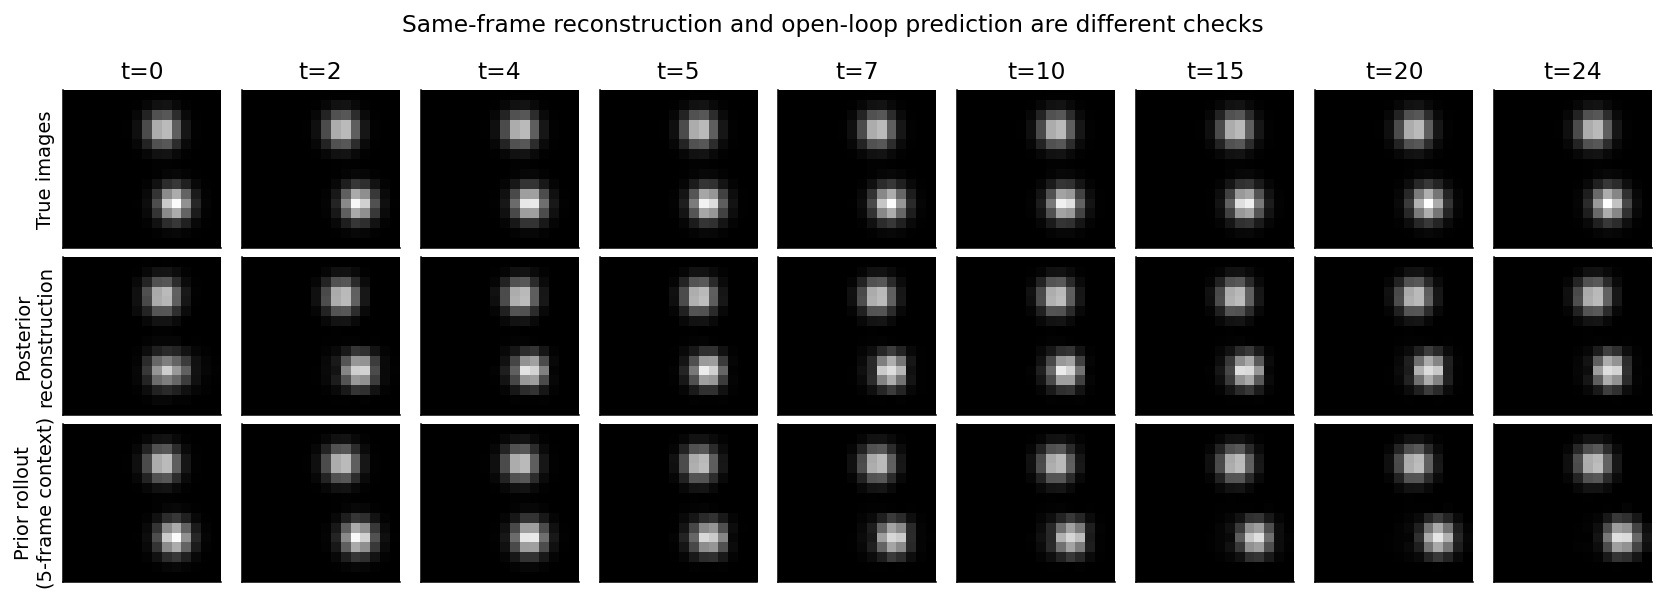

In [19]:
import base64
display(Image(data=base64.b64decode('...')))

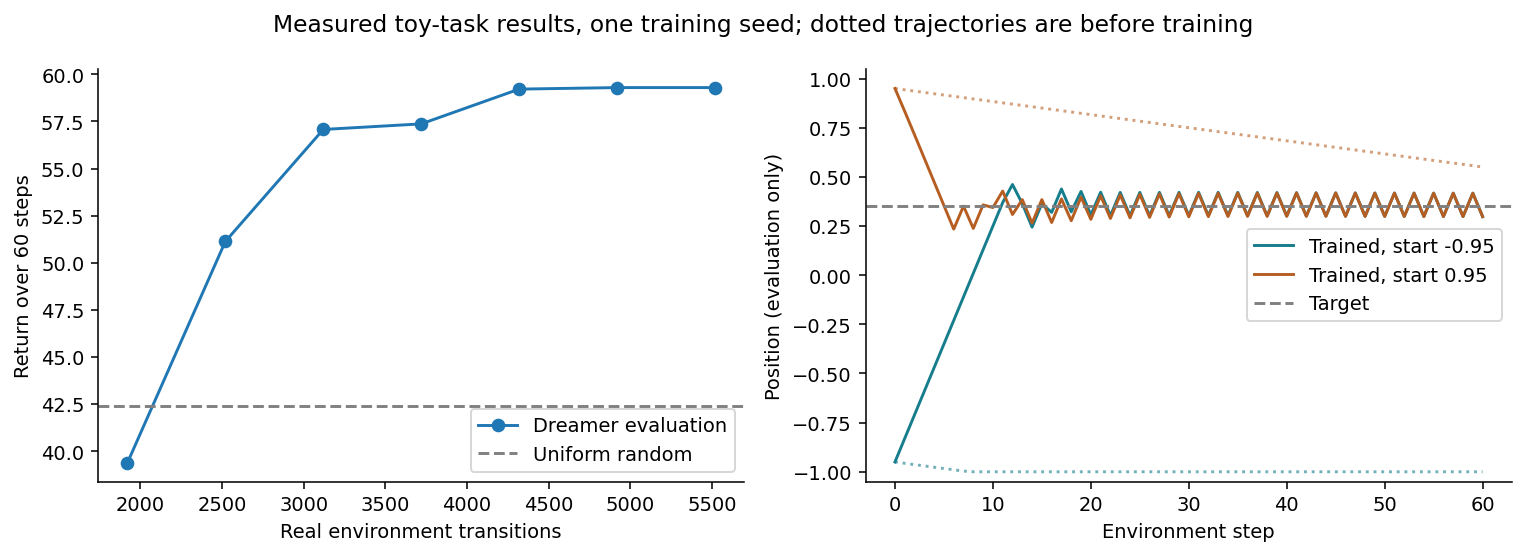

In [20]:
import base64
display(Image(data=base64.b64decode('...')))

训练结果是直接嵌入的真实记录与图像，因此单独打开这个 Notebook 也可以阅读。下面可选地加载同包最终权重，对第一张图像做真实推断。

In [21]:
checkpoint_path = Path('results/checkpoint.pt')
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    loaded_cfg = Config(**checkpoint['config'])
    loaded_cfg.device = 'cpu'
    loaded = Dreamer(loaded_cfg)
    loaded.wm.load_state_dict(checkpoint['world_model'])
    loaded.actor.load_state_dict(checkpoint['actor'])
    loaded.critic.load_state_dict(checkpoint['critic'])
    obs = PixelReach(0).reset(x=-0.8)
    with torch.no_grad():
        state = loaded.wm.infer_observation(torch.tensor(obs[None]))
        action = loaded.actor(loaded.wm.features(state), sample=False)
    print('最终模型，在 x=-0.8 对应图像上的第一个动作:', action.item())
else:
    print('单独打开 Notebook：已嵌入结果可正常阅读；加载权重需要同包 results/checkpoint.pt。')

最终模型，在 x=-0.8 对应图像上的第一个动作: 0.9999045133590698


## 15. 和原论文有哪些明确不同？

| 项目 | 原论文连续控制设定 | 本教学 demo |
|---|---|---|
| 任务 | 多种视觉控制 benchmark | 自包含的一维滑块对齐 |
| 图像网络 | CNN / 转置 CNN | MLP / MLP，16×16 灰度图 |
| RSSM | 随机潜变量 30 维 | h=64，z=8 |
| batch / sequence | 50 / 50 | 16 / 16 |
| imagination H | 15 | 12 |
| γ / λ | 0.99 / 0.95 | 0.97 / 0.95 |
| free nats | 3 | 1 |
| 高斯观测尺度 | 原实现配置 | 图像/奖励 σ 都为 0.3，改变 loss 比例 |
| 学习率 | WM 6e-4，Actor/Critic 8e-5 | WM 1e-3，Actor/Critic 3e-4 |
| 训练调度 | seed 后交替训练 | 增加 400 次 WM warmup，之后交替训练 |
| imagination 起点 | 序列中模型状态 | 跳过每段最初四步后抽取最多 64 个起点 |
| 在线行动与评估 | 原实现动作分布处理 | 后验均值 + tanh(高斯均值)，收集时另加噪声 |
| target critic / entropy bonus | 论文称不需要 | 都没有添加 |
| terminal / discount head | 提前终止任务按需使用 | 环境无终止，仅固定 γ |

`tanh(高斯均值)` 是确定性的动作选择规则，一般并不严格等于 tanh 后分布的数学众数。训练 Actor 时仍然使用完整随机 `rsample()`；开放预测图为了便于比较使用 Prior 均值，不展示抽样方差。

保留的是原始 Dreamer 的核心：随机 RSSM、Posterior/Prior、图像与奖励似然、KL、潜空间想象、重参数化动作、λ-return、Dynamics gradient、分开更新世界模型/Actor/Critic。这里没有加入 DreamerV2 的离散 latent、KL balancing，也没有加入 DreamerV3 的 symlog/two-hot 等机制。

## 来源与公式对照

- 上传论文第 3 页 Figure 3 / Algorithm 1：模型学习、行为学习、真实交互三阶段。
- 第 4 页式 (3)：连续动作的重参数化；式 (5)、(6)：多步 target 与 λ-return。
- 第 5 页式 (7)、(8)：Actor 最大化回报、Critic 回归 target，以及冻结世界模型。
- 第 6 页式 (9)、(10)：重建版本的世界模型与 ELBO/VIB。
- 第 14 页 Appendix A：free nats、学习率、没有 target value network / entropy bonus 等设定。
- [论文公开版本](https://arxiv.org/abs/1912.01603)
- [作者维护的原始 Dreamer 代码](https://github.com/danijar/dreamer)
- [PyTorch distributions：采样与路径导数](https://docs.pytorch.org/docs/2.14/distributions.html#pathwise-derivative)